# End-to-end rockburst assessment demo (RC10)

Rules FSM path (no LLM). Pipeline: **raw CSV → preprocess → load models by file hash → evaluation tables → ≥3 held-out assessments**.

Execute with:
```bash
jupyter nbconvert --to notebook --execute notebooks/end_to_end_demo.ipynb --inplace
```
Do not use a custom `exec()` runner. Ship saved outputs after execution.

In [1]:
import hashlib
import json
import warnings
from pathlib import Path

import pandas as pd

from rockburst.config import load_config, resolve_path

warnings.filterwarnings('ignore', message='IProgress not found.*')
warnings.filterwarnings('ignore', message='Unknown solver options: disp')
cfg = load_config()
root = Path(cfg.get('_root', '.')).resolve()

def rel(p):
    try:
        return str(Path(p).resolve().relative_to(root))
    except Exception:
        return str(p)

def file_sha256(path: Path, nbytes: int | None = None) -> str:
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        if nbytes is None:
            for chunk in iter(lambda: f.read(1 << 20), b''):
                h.update(chunk)
        else:
            h.update(f.read(nbytes))
    return h.hexdigest()

raw_csv = root / 'data' / 'raw' / 'rockburst.csv'
print('repository root', '.')
print('raw CSV', rel(raw_csv))
print('processed CSV', rel(resolve_path(cfg, 'processed_csv')))
print('models', rel(resolve_path(cfg, 'models')))

repository root .
raw CSV data/raw/rockburst.csv
processed CSV data/processed/rockburst_processed.csv
models artifacts/models


## 1. Raw CSV → preprocess

Load Table S1 and the processed frame used by training (identities recomputed in `rockburst.data` / CLI `extract`).

In [2]:
raw_path = root / 'data' / 'raw' / 'rockburst.csv'
proc_path = resolve_path(cfg, 'processed_csv')
assert raw_path.exists(), f'Missing {raw_path}'
assert proc_path.exists(), f'Missing {proc_path}; run: python -m rockburst.cli extract'

from rockburst.data import process_raw

raw = pd.read_csv(raw_path)
proc, preprocess_audit = process_raw(raw, cfg)
stored_proc = pd.read_csv(proc_path)
pd.testing.assert_frame_equal(
    proc.reset_index(drop=True), stored_proc.reset_index(drop=True),
    check_dtype=False, rtol=1e-12, atol=1e-12,
)
print('Raw-to-processed value check OK')
print('raw', raw.shape, 'processed', proc.shape)
print('grade counts:\n', proc['rockburst_grade'].value_counts().sort_index())
print('missing D fraction', float(proc['d'].isna().mean()))
proc.head(3)

Raw-to-processed value check OK
raw (344, 10) processed (344, 11)
grade counts:
 rockburst_grade
0     50
1     98
2    123
3     73
Name: count, dtype: int64
missing D fraction 0.3808139534883721


,no,sigma_theta,sigma_c,sigma_t,scf,b1,b2,wet,d,rockburst_grade,dup_group_id
0,1,90.0,170.0,11.3,0.53,15.04,0.88,9.0,200.0,2,0
1,2,90.0,220.0,7.4,0.41,29.73,0.93,7.3,194.0,1,1
2,3,62.6,165.0,9.4,0.38,17.53,0.89,9.0,400.0,1,2


## 2. Train **or** load final models by file hash

This demo **loads** shipped models (no Optuna). Hashes pin the artefacts used for assessments below.

In [3]:
models = resolve_path(cfg, 'models')
required = ['best_baseline.joblib', 'fusion.joblib']
hashes = {}
for name in required:
    p = models / name
    assert p.exists(), f'Missing {p}; run: python -m rockburst.cli train'
    hashes[name] = file_sha256(p)
    print(f'{name}: sha256={hashes[name][:16]}…  size={p.stat().st_size}')

m1_path = resolve_path(cfg, 'baselines') / 'm1_results.json'
m1 = json.loads(m1_path.read_text())
print('best_model', m1.get('best_model'))
print('run_metadata', m1.get('run_metadata'))

best_baseline.joblib: sha256=cd021e614b34b9d4…  size=1332613
fusion.joblib: sha256=b6dfdfd146caa346…  size=50538
best_model lightgbm__median
run_metadata {'mode': 'full', 'git_hash': 'b48325e17c103536c6fe0ebf3ba59d476d4420aa', 'git_dirty': False, 'rockburst_version': '0.1.0', 'package_versions': {'numpy': '2.5.3', 'pandas': '3.0.6', 'scikit-learn': '1.9.1', 'scipy': '1.18.1', 'joblib': '1.6.0', 'optuna': '5.0.0', 'catboost': '1.2.10', 'xgboost': '3.4.1', 'lightgbm': '4.7.0'}, 'command': 'rockburst train', 'configuration_sha256': 'a40baeb5dbfe6743400ce14414837436bb9571cccf81820550764b4e8d307e8f', 'input_sha256': {'data/processed/rockburst_processed.csv': '5be436a3711623b2c40ceb0c7cb7be5e19ccc15bfb323d6fcb7f7197d797f54d'}, 'n_outer': 5, 'n_inner': 3, 'n_trials': 50, 'best_model': 'lightgbm__median', 'started_date_utc': '2026-10-27T23:16:43Z', 'completed_date_utc': '2026-10-27T23:18:44Z', 'git_state_scope': 'captured before generated artefacts were written'}


## 3. Evaluation tables (full-mode artefacts)

Numbers from `headline_snapshot.json` / baselines — regenerate via `scripts/generate_figures.py` after `evaluate`.

In [4]:
base = resolve_path(cfg, 'baselines')
snap_path = base / 'headline_snapshot.json'
abl_path = base / 'ablation_results.json'
assert snap_path.exists() and abl_path.exists()
snap = json.loads(snap_path.read_text())
abl = json.loads(abl_path.read_text())
assert abl.get('quick') is False, 'RC1: refuse quick ablation numbers'

print('=== Headline ===')
print(json.dumps({
    'best_model': snap.get('best_model'),
    'nested_unbiased_qwk': snap.get('nested_unbiased_qwk'),
    'production_qwk_pooled': snap.get('production_qwk_pooled'),
    'ablation_M1_qwk': snap.get('ablation_M1_qwk'),
    'ablation_M7_abstention': snap.get('ablation_M7_abstention'),
    'conformal_method': snap.get('conformal_method'),
    'conformal_coverage': snap.get('conformal_coverage'),
}, indent=2))

print('\n=== Matched coverage (RC4) ===')
mc = abl.get('matched_coverage') or {}
print('same prediction population N=', mc.get('n_total'))
for name, block in (mc.get('comparisons') or {}).items():
    delta = block.get('delta_system_minus_m1') or {}
    print(f"  {name}: coverage={block.get('coverage'):.3f} n={block.get('n_accepted')} "
          f"delta_acc={delta.get('accuracy'):+.3f} CI={delta.get('accuracy_ci95')}")

rc = abl.get('risk_coverage_max_prob_vs_r_final') or {}
print('\n=== RC max-prob vs R_final ===')
print(json.dumps(rc, indent=2)[:600])

=== Headline ===
{
  "best_model": "lightgbm__median",
  "nested_unbiased_qwk": 0.7034585528139727,
  "production_qwk_pooled": 0.6970885241350593,
  "ablation_M1_qwk": {
    "mean": 0.669951155562134,
    "std": 0.024280026431932413,
    "ci95_low": 0.6218271792683865,
    "ci95_high": 0.7170540879949087,
    "method": "grouped_bootstrap"
  },
  "ablation_M7_abstention": {
    "mean": 0.32558139534883723,
    "std": 0.013717364656664885,
    "ci95_low": 0.2989764563106796,
    "ci95_high": 0.3525606111672846,
    "method": "grouped_bootstrap"
  },
  "conformal_method": "marginal_split",
  "conformal_coverage": 0.9188405797101449
}

=== Matched coverage (RC4) ===
same prediction population N= 1720
  M3: coverage=0.899 n=1547 delta_acc=-0.006 CI=[-0.023582636970381026, 0.009389557164948922]
  M4: coverage=0.471 n=810 delta_acc=-0.038 CI=[-0.07012508181966946, -0.01264517021015113]
  M5: coverage=0.830 n=1427 delta_acc=-0.011 CI=[-0.024375913020571367, 0.0013643090976809473]
  M6: coverag

## 4. ≥3 held-out assessments (live `run_graph` / routes + R_final)

**Primary evidence (RC10):** fit one outer-fold pipeline and run the rules FSM live on ≥3 outer-test cases. Print `case_no`, route, and `R_final`.

JSON dumps under `artifacts/examples/` are secondary (next cell); regenerate with `scripts/generate_examples.py`.

In [5]:
import importlib.util

# Reuse Phase-6 held-out fold helpers (rules FSM; no LLM).
_gen_path = root / 'scripts' / 'generate_examples.py'
_spec = importlib.util.spec_from_file_location('gen_ex_nb', _gen_path)
_gen = importlib.util.module_from_spec(_spec)
assert _spec.loader is not None
_spec.loader.exec_module(_gen)

ctx = _gen._fit_fold_context(cfg, fold_index=0)
assert ctx is not None, 'Need artifacts/baselines/m1_results.json (run rockburst train)'
te_nos = ctx['df'].iloc[ctx['te']]['no'].astype(int).tolist()
assert len(te_nos) >= 3, 'Outer test fold too small'
live_cases = te_nos[:3]

print(f'Live held-out fold={ctx["fold_index"]} model={ctx["best"]} n_test={len(te_nos)}')
print('Assessing case_nos:', live_cases)
print()

live_results = []
for no in live_cases:
    result = _gen._assess_heldout(ctx, int(no))
    live_results.append(result)
    route = result.get('route_trace') or []
    r_final = result.get('final_system_confidence')
    print('=' * 50)
    print(f"case_no={result.get('case_no')}  true={result.get('true_intensity')}  "
          f"pred={result.get('predicted_intensity')}  action={result.get('recommended_action')}")
    print(f"R_final={r_final}")
    print('route:', ' → '.join(str(s) for s in route[:14]), ('…' if len(route) > 14 else ''))

assert len(live_results) >= 3
assert all(r.get('case_no') is not None for r in live_results)
print('\nRC10 live assess OK:', [r.get('case_no') for r in live_results])

Live held-out fold=0 model=lightgbm__median n_test=69
Assessing case_nos: [6, 8, 13]



case_no=6  true=moderate  pred=light  action=accept_with_caution
R_final=0.7295998146298323
route: rules:data_quality → rules:geomechanics_skipped → rules:predict → rules:uncertainty → rules:extra_validation → rules:critic → rules:recheck_physics → rules:critic → rules:finalize 


case_no=8  true=moderate  pred=light  action=abstain
R_final=0.4933590351476354
route: rules:data_quality → rules:geomechanics_skipped → rules:predict → rules:uncertainty → rules:extra_validation → rules:critic → rules:recheck_model → rules:critic → rules:recheck_physics → rules:critic → rules:finalize 


case_no=13  true=moderate  pred=moderate  action=accept_with_caution
R_final=0.8165225390804133
route: rules:data_quality → rules:geomechanics → rules:predict → rules:uncertainty → rules:extra_validation → rules:critic → rules:recheck_model → rules:critic → rules:finalize 

RC10 live assess OK: [6, 8, 13]


### 4b. Secondary: shipped example JSON (optional)

Read previously generated held-out JSON for comparison. Live assess above is the RC10 primary evidence.

In [6]:
ex = resolve_path(cfg, 'examples')
heldouts = sorted(ex.glob('heldout_case_*.json'))
if len(heldouts) < 1:
    print('No heldout_case_*.json yet — run scripts/generate_examples.py')
else:
    for p in heldouts[:5]:
        blob = json.loads(p.read_text())
        print('=' * 50, rel(p))
        for k in [
            'case_no', 'true_grade', 'true_intensity', 'predicted_intensity',
            'recommended_action', 'final_system_confidence', 'abstained',
            'fold_index', 'fold_model', 'example_protocol', 'delivered_planner',
        ]:
            print(f'  {k}: {blob.get(k)}')
        trace = blob.get('route_trace') or []
        print('  route:', ' → '.join(str(s) for s in trace[:12]), ('…' if len(trace) > 12 else ''))

fa = ex / 'failure_analysis.md'
print('\n--- failure_analysis.md ---')
print(fa.read_text() if fa.exists() else 'missing — run generate_examples.py')

================================================== artifacts/examples/heldout_case_28.json
  case_no: 28
  true_grade: 1
  true_intensity: light
  predicted_intensity: light
  recommended_action: accept_with_caution
  final_system_confidence: 0.8784031558387193
  abstained: False
  fold_index: 0
  fold_model: lightgbm__median
  example_protocol: held_out_fold; rules FSM; relative paths only; fold=0; model=lightgbm__median
  delivered_planner: rules_fsm
  route: rules:data_quality → rules:geomechanics → rules:predict → rules:uncertainty → rules:extra_validation → rules:critic → rules:recheck_physics → rules:critic → rules:finalize 
================================================== artifacts/examples/heldout_case_48.json
  case_no: 48
  true_grade: 0
  true_intensity: none
  predicted_intensity: none
  recommended_action: accept_with_caution
  final_system_confidence: 0.8719159615351036
  abstained: False
  fold_index: 0
  fold_model: lightgbm__median
  example_protocol: held_out_fold; 

## 5. Key figures (F1 / F8 / F12)

Full set F1–F17 under `artifacts/figures/` after `scripts/generate_figures.py`.

F01_system_architecture.png OK 153099 bytes


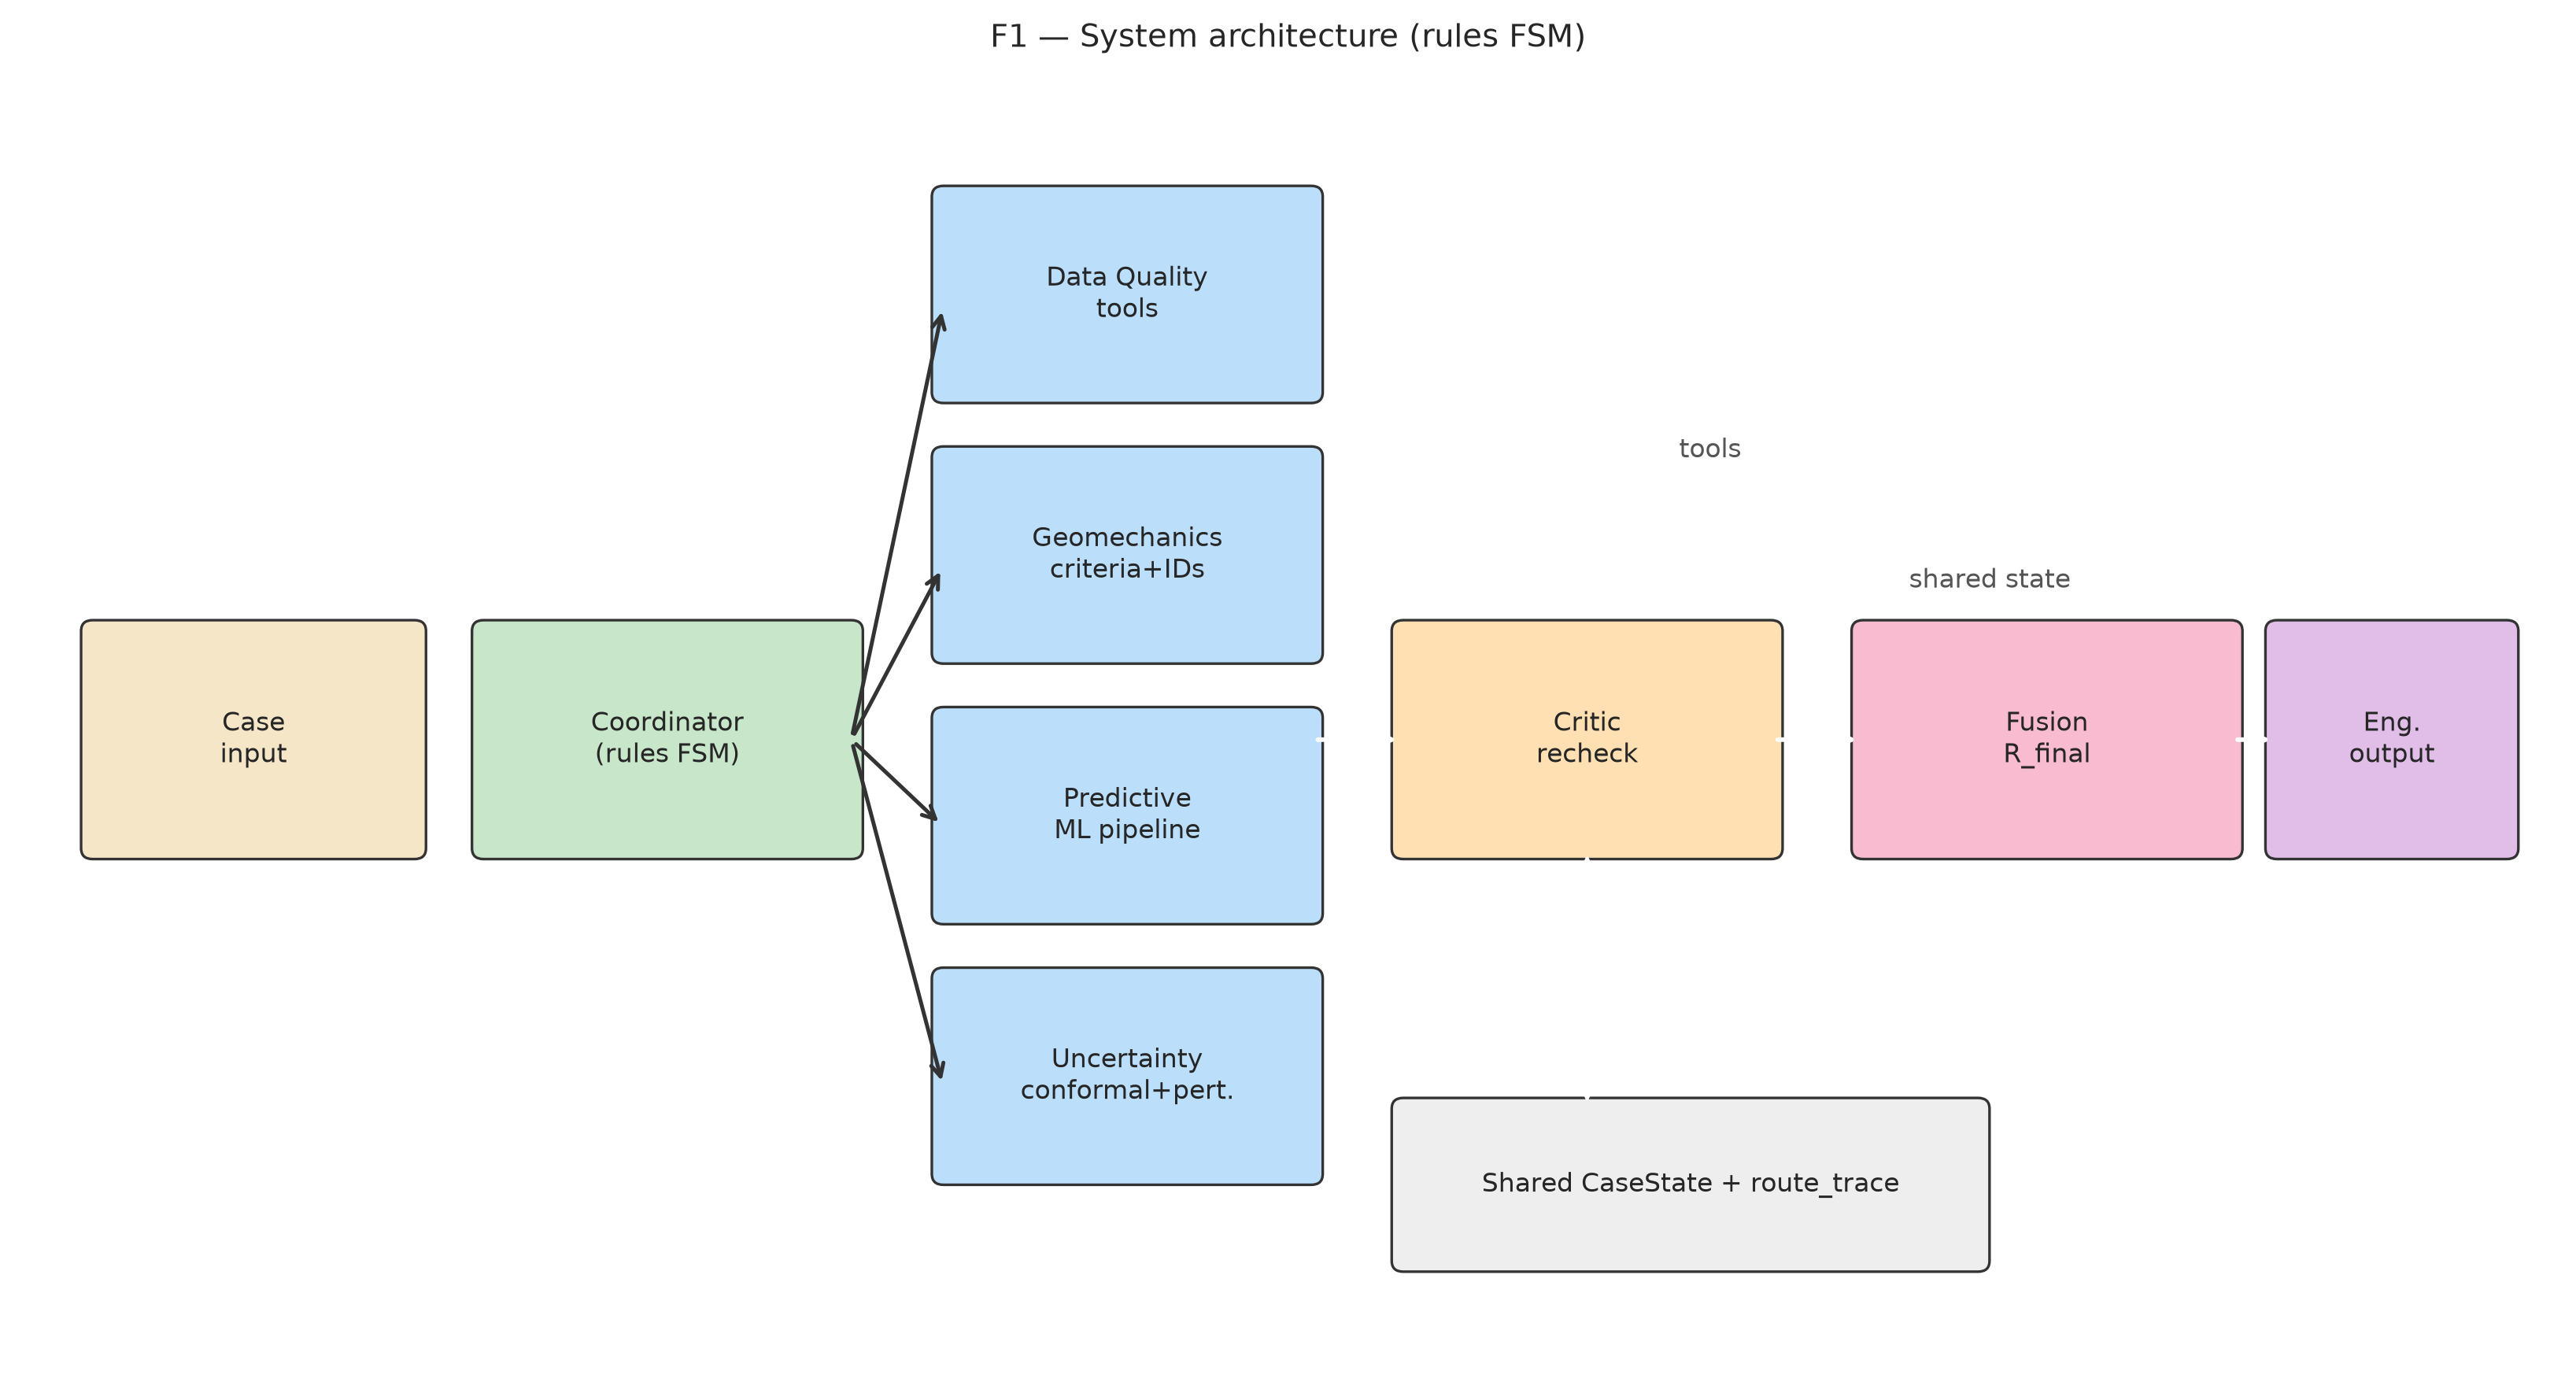

F08_model_comparison.png OK 546383 bytes


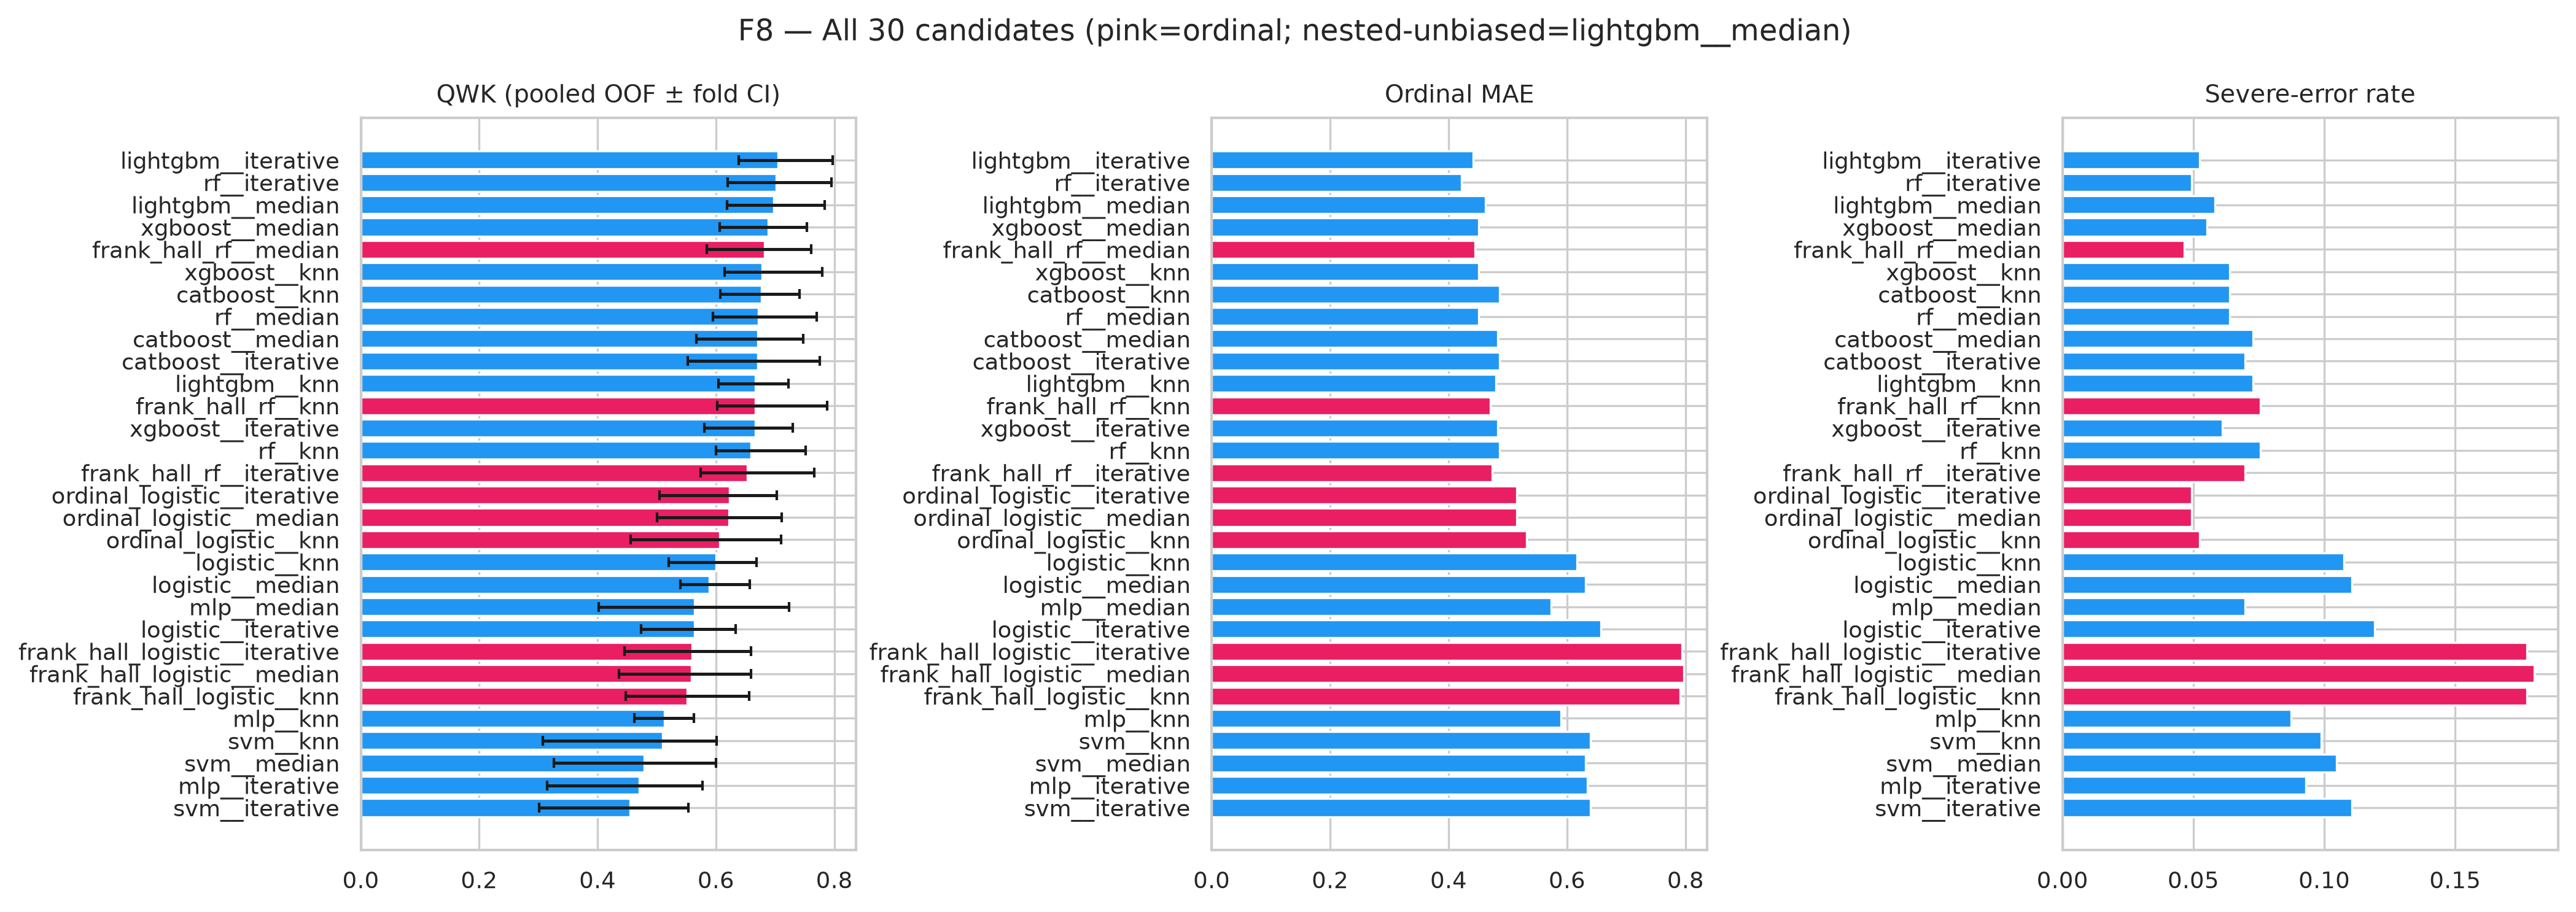

F12_conformal.png OK 169992 bytes


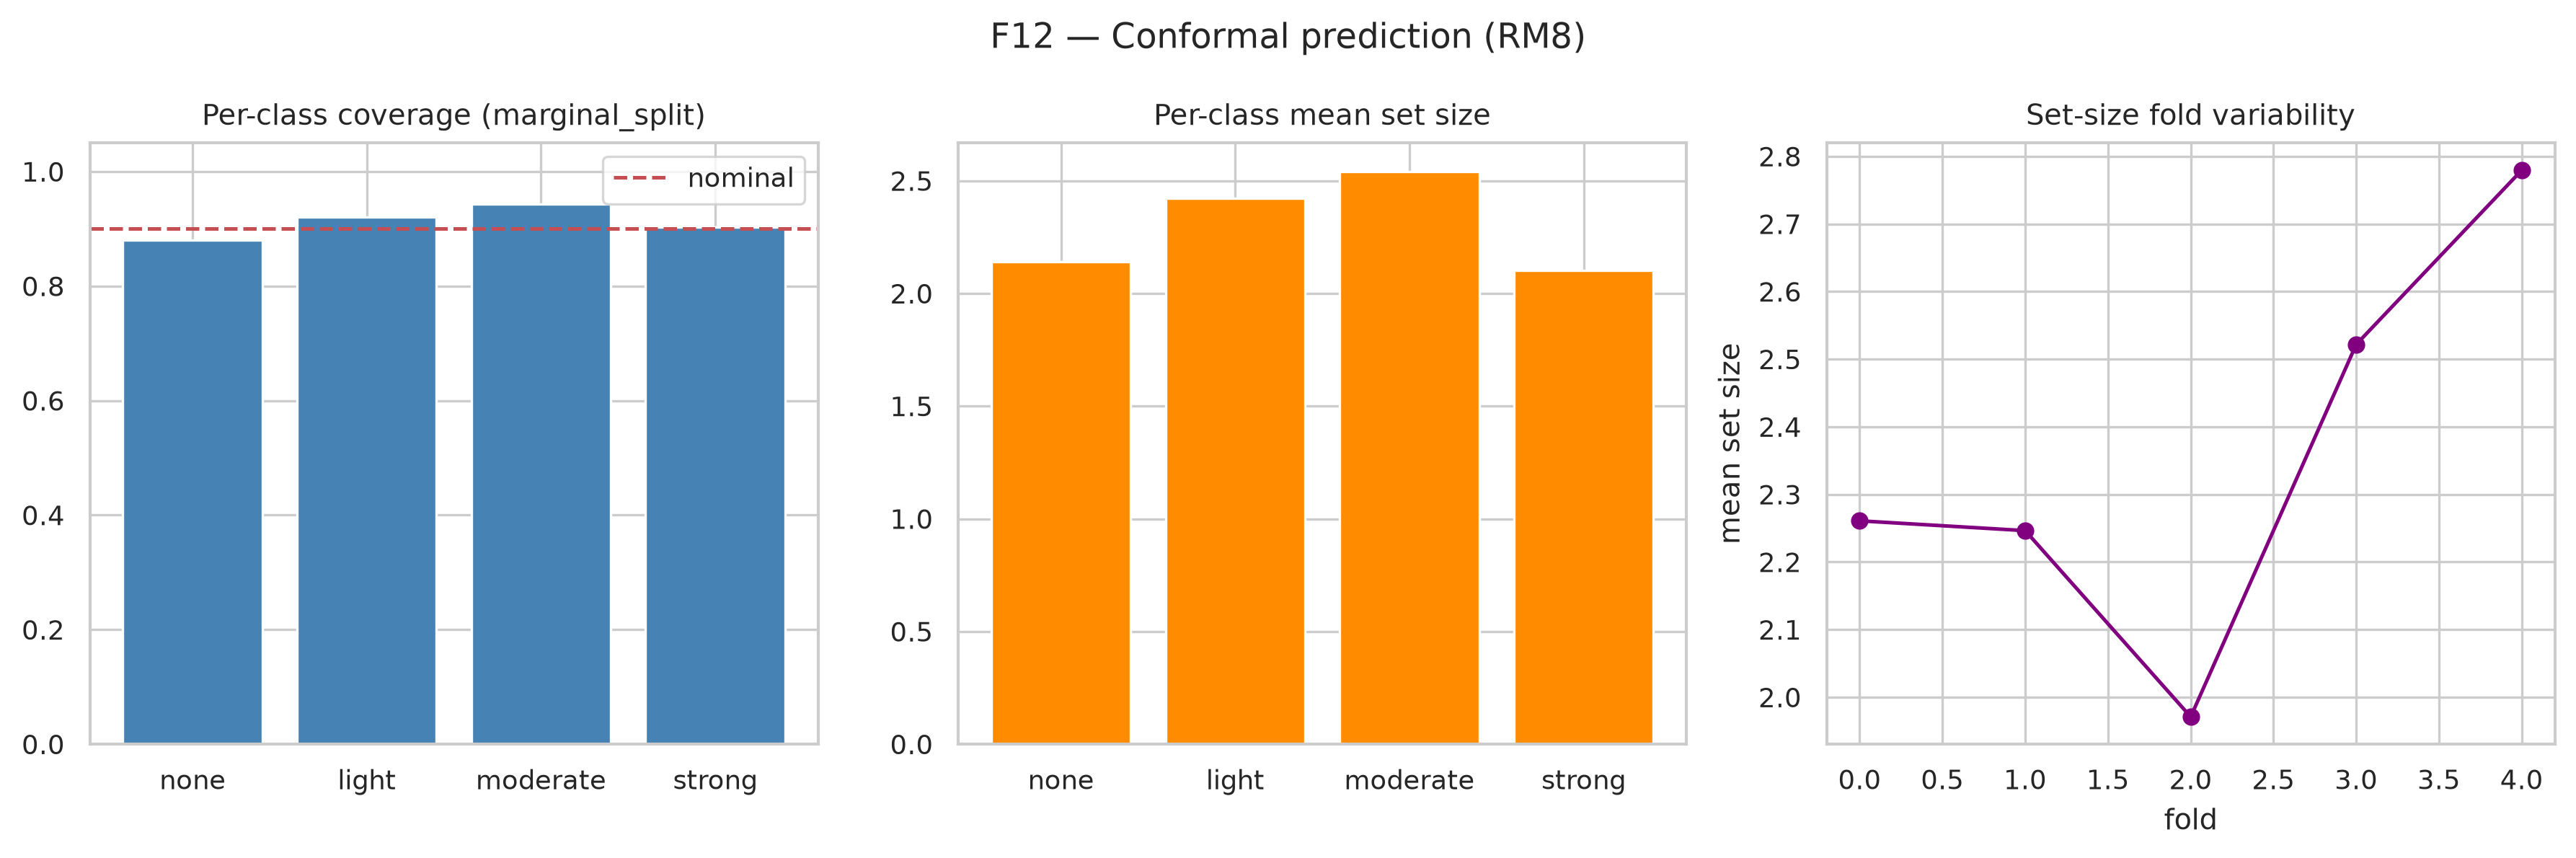

In [7]:
from IPython.display import Image, display

fig_dir = resolve_path(cfg, 'artifacts') / 'figures'
for name in [
    'F01_system_architecture.png',
    'F08_model_comparison.png',
    'F12_conformal.png',
]:
    p = fig_dir / name
    print(name, 'OK' if p.exists() else 'MISSING', p.stat().st_size if p.exists() else 0, 'bytes')
    if p.exists():
        display(Image(filename=str(p), width=720))